In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# Contract timing and the real wage loss after the 2021-23 inflation shock
Notebook 36 compared countries: collective-bargaining coverage and union density against the pass-through of inflation to wages (21-23 countries, nothing found). Here the question moves inside Italy, where **collective agreements are renewed with long and uneven delays**, and the data give many more observations: Istat's index of **contractual hourly wages** for 113 agreement groups (`155_318_DF_DCSC_RETRCONTR1C_4`, base December 2021 = 100, monthly since 2005) and its **bargaining-tension indicators** (share of employees whose contract has expired and the months they have waited, for six aggregates, `149_319_DF_DCSC_RETRCONTR1T`).

**Design.** Contractual wages move when an agreement's increment takes effect, so each group's index is a staircase. For every leaf group (no sub-group: 67 private, 13 public; 78 with data over the window) at December 2021, the eve of the shock: **staleness** = months since the last increment (a month-on-month rise of at least 0.25% of the index) and **standstill** = months without an increment among the 24 before. Outcome: the **real change** of the contractual wage between December 2021 and December 2024 (and 2025), the index change deflated by Italy's cumulative December-on-December HICP inflation (4.2%, 12.2%, 0.6%, 1.3% and 1.2% in 2021-2025: 14.3% to 2024, 15.7% to 2025). The question, exploratory and two-sided: do groups whose agreement was already old when the shock began end up with a different real loss? Spearman rank correlation with a permutation p, BH over the pre-specified family (two predictors, two horizons), leave-one-group-out, a calm-period placebo (December 2016 to 2019) and a shuffled-outcome null.

**A change of unit, declared.** The sub-sectors under one parent group (for instance the manufacturing branches) share the same national agreements, so their staircases are not 78 independent observations. The first test was run on the 78 leaves, and its p-value turned out to depend on the null used (0.002 shuffling within the private and public branch, 0.5 shuffling within parent groups). The **primary analysis is therefore on the 30 parent groups** (means of their sub-sectors; the permutation shuffles within the private and public branch); the leaf-level tests are kept as sensitivity and are reported with their caveat. This choice was made after seeing the leaf-level results, not before.

**Limits of the data.** Contractual wages exclude wage drift, bonuses outside the agreements and one-off payments; the groups are Ateco sectors, not contracts, and carry no employee weights; the number of workers per agreement is not in the flows, and renewal dates come from CNEL's archive (section E) for 74 of the 78 leaves through a hand-made mapping. Descriptive associations only.

In [2]:
from cifresignificative.analysis import contracts as CT, experiments as ex
from cifresignificative.analysis.hf import load_highfreq
cres = ex.run_contracts_all()
leaves, clu = cres["c1_leaf_groups"].set_index("group"), cres["c12_clusters"].set_index("group")
dec = CT.december_inflation(load_highfreq())
print("December-on-December HICP inflation, Italy (%):", dec.loc[2016:2025].round(1).to_dict(), "| cumulative 2021-24:", round(CT.cumulative_inflation(dec, 2021, 2024), 1), "| 2021-25:", round(CT.cumulative_inflation(dec, 2021, 2025), 1))
print("leaf groups with data:", len(leaves), leaves.branch.value_counts().to_dict(), "| parent groups:", len(clu), "with", clu.n_leaves.value_counts().sort_index().to_dict(), "sub-sectors each")
print("leaf groups, medians by branch (nominal and real change of the contractual wage Dec 2021 - Dec 2024, %; staleness and standstill in months at Dec 2021):"); display(leaves.groupby("branch")[["nominal_change", "real_change", "staleness_months", "standstill_24m"]].median().round(2))
print("share of leaf groups with a real loss by Dec 2024:", round(float((leaves.real_change < 0).mean()), 3), "| by Dec 2025:", round(float((leaves.real_change_25 < 0).mean()), 3), "| range of real change to 2024:", round(float(leaves.real_change.min()), 1), "to", round(float(leaves.real_change.max()), 1))
print("aggregates (Istat's own aggregates; nominal and real change, %):"); display(cres["c10_aggregates"].set_index(["end", "group"])[["name_en", "staleness_months", "standstill_24m", "nominal_change", "real_change"]].round(2))

December-on-December HICP inflation, Italy (%): {2016: 0.6, 2017: 1.0, 2018: 1.1, 2019: 0.5, 2020: -0.2, 2021: 4.2, 2022: 12.2, 2023: 0.6, 2024: 1.3, 2025: 1.2} | cumulative 2021-24: 14.3 | 2021-25: 15.7
leaf groups with data: 78 {'private': 65, 'public': 13} | parent groups: 30 with {1: 5, 2: 13, 3: 7, 4: 1, 5: 2, 6: 2} sub-sectors each
leaf groups, medians by branch (nominal and real change of the contractual wage Dec 2021 - Dec 2024, %; staleness and standstill in months at Dec 2021):


,nominal_change,real_change,staleness_months,standstill_24m
branch,,,,
private,7.5,-5.98,9.0,23.0
public,7.3,-6.16,29.0,24.0


share of leaf groups with a real loss by Dec 2024: 0.885 | by Dec 2025: 0.859 | range of real change to 2024: -12.5 to 5.6
aggregates (Istat's own aggregates; nominal and real change, %):


name_en  staleness_months  standstill_24m  \
end  group                                                       
2024 Z0010       agricolture               5.0            23.0   
     Z0060          industry               6.0            22.0   
     Z1240  private services              11.0            22.0   
     Z2520    private sector               6.0            22.0   
     Z3620     total economy               6.0            23.0   
2025 Z0010       agricolture               5.0            23.0   
     Z0060          industry               6.0            22.0   
     Z1240  private services              11.0            22.0   
     Z2520    private sector               6.0            22.0   
     Z3620     total economy               6.0            23.0   

            nominal_change  real_change  
end  group                               
2024 Z0010             9.5        -4.23  
     Z0060            11.3        -2.66  
     Z1240             6.3        -7.03  
     Z2520             8.7        -4.93  
     Z3620             8.2        -5.37  
2025 Z0010            11.4        -3.73  
     Z0060            13.7        -1.74  
     Z1240             9.6        -5.28  
     Z2520            11.5        -3.64  
     Z3620            11.3        -3.81

PRIMARY - 30 parent groups (x shuffled within the private and public branch; BH over the four tests):


,x,y,n,rho,p,q_value,loo_min,loo_max
0,staleness_months,real_change,30,-0.583,0.001,0.001,-0.644,-0.552
1,staleness_months,real_change_25,30,-0.551,0.001,0.001,-0.621,-0.520
2,standstill_24m,real_change,30,-0.523,0.001,0.001,-0.596,-0.483
3,standstill_24m,real_change_25,30,-0.513,0.001,0.001,-0.584,-0.468


private parent groups only:


,x,y,n,rho,p,q_value,loo_min,loo_max
0,staleness_months,real_change,26,-0.60,0.001,0.002,-0.667,-0.567
1,standstill_24m,real_change,26,-0.58,0.002,0.002,-0.643,-0.543


step threshold (0.15%, 0.25%, 0.5%) - 2024 outcome:


,step,x,n,rho,p
0,0.002,staleness_months,30,-0.591,0.001
1,0.002,standstill_24m,30,-0.527,0.001
2,0.002,staleness_months,30,-0.583,0.001
3,0.002,standstill_24m,30,-0.523,0.001
4,0.005,staleness_months,30,-0.499,0.003
5,0.005,standstill_24m,30,-0.480,0.003


... (4 outputs left out)

PLACEBO - the same test for December 2016 to December 2019 (cumulative inflation 2.6%):


,x,y,n,rho,p,q_value,loo_min,loo_max
0,staleness_months,real_change,29,-0.058,0.869,0.869,-0.160,0.002
1,standstill_24m,real_change,29,0.060,0.866,0.869,-0.039,0.118


shuffled-outcome null, 200 shuffles: mean discoveries 0.065 | shuffles with a discovery 0.045 | share of p < 0.05 0.049
mechanism check on the parent groups (steps_after = months with an increment between Dec 2021 and Dec 2024):


,x,y,n,rho
0,standstill_24m,steps_after,30,-0.175
1,steps_after,real_change,30,0.446
2,staleness_months,steps_after,30,-0.395


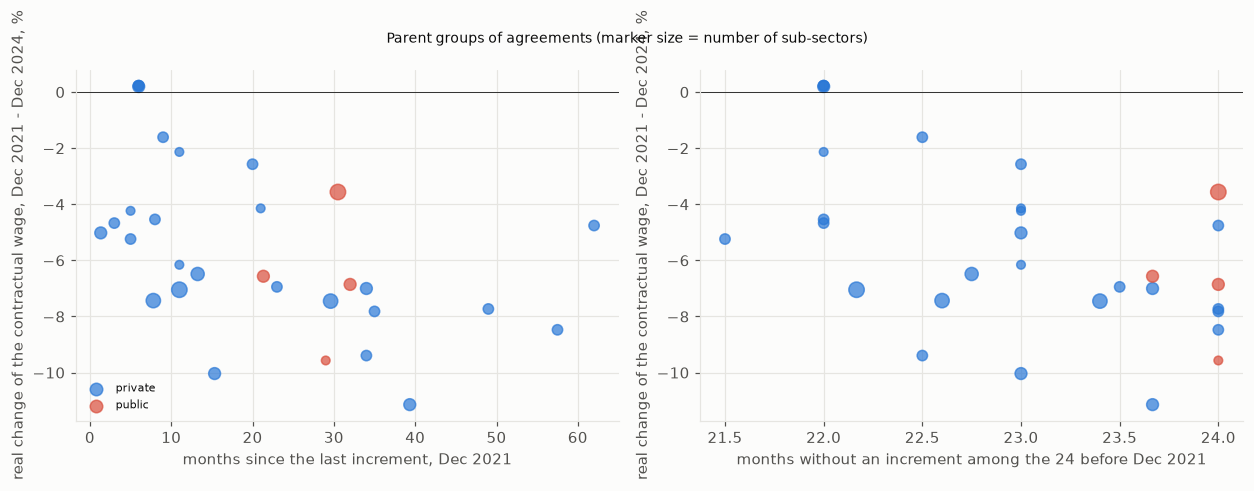

In [3]:
cols = ["x", "y", "n", "rho", "p", "q_value", "loo_min", "loo_max"]
print("PRIMARY - 30 parent groups (x shuffled within the private and public branch; BH over the four tests):"); display(cres["c2_cluster_family"][cols].round(3))
print("private parent groups only:"); display(cres["c5_cluster_private"][cols].round(3))
print("step threshold (0.15%, 0.25%, 0.5%) - 2024 outcome:"); display(cres["c6_cluster_thresholds"][["step", "x", "n", "rho", "p"]].round(3))
print("SENSITIVITY - 78 leaf groups, x shuffled within branch (anti-conservative: sub-sectors share contracts):"); display(cres["c3_leaf_family_branch"][cols].round(3))
print("SENSITIVITY - 78 leaf groups, x shuffled within parent group (conservative: removes the between-parent variation):"); display(cres["c4_leaf_family_within_parent"][cols].round(3))
print("PLACEBO - the same test for December 2016 to December 2019 (cumulative inflation 2.6%):"); display(cres["c7_placebo_2016_19"][cols].round(3))
nl = cres["c8_null"]; print("shuffled-outcome null,", len(nl), "shuffles: mean discoveries", round(float(nl.discoveries.mean()), 3), "| shuffles with a discovery", round(float((nl.discoveries > 0).mean()), 3), "| share of p < 0.05", round(float(nl.share_p_below_005.mean()), 3))
print("mechanism check on the parent groups (steps_after = months with an increment between Dec 2021 and Dec 2024):"); display(cres["c11_persistence"].round(3))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, x, lab in ((axes[0], "staleness_months", "months since the last increment, Dec 2021"), (axes[1], "standstill_24m", "months without an increment among the 24 before Dec 2021")):
    for br, colr in (("private", "#2a78d6"), ("public", "#d94f3d")):
        s = clu[clu.branch == br]; ax.scatter(s[x], s.real_change, s=18 + 14 * s.n_leaves, color=colr, alpha=.7, label=br)
    ax.axhline(0, color="k", lw=.5); ax.set_xlabel(lab); ax.set_ylabel("real change of the contractual wage, Dec 2021 - Dec 2024, %")
axes[0].legend(fontsize=7); fig.suptitle("Parent groups of agreements (marker size = number of sub-sectors)", fontsize=9); plt.tight_layout(); plt.show()

bargaining tension at December of each year (base 2015 up to 2020, base 2021 from 2021; not spliced): share of employees with an expired contract (%), months of waiting averaged over all employees:


,year,base,employees_expired_pct|private sector,employees_expired_pct|public administration,employees_expired_pct|total economy,months_all|private sector,months_all|public administration,months_all|total economy
0,2015,2015,22.6,100.0,40.3,8.2,72.0,22.8
1,2016,2015,35.9,100.0,50.5,11.5,84.0,28.1
2,2017,2015,23.2,100.0,40.8,10.2,96.0,29.8
3,2018,2015,32.4,0.1,25.0,6.6,0.1,5.1
4,2019,2015,28.1,100.0,44.6,8.2,12.1,9.1
5,2020,2015,75.3,100.0,80.9,13.9,24.1,16.3
6,2021,2021,39.8,100.0,52.9,11.1,36.1,16.5
7,2022,2021,35.0,100.0,49.1,13.1,12.0,12.9
8,2023,2021,38.0,100.0,51.5,16.6,24.0,18.2
9,2024,2021,37.1,100.0,50.8,4.1,36.0,11.0


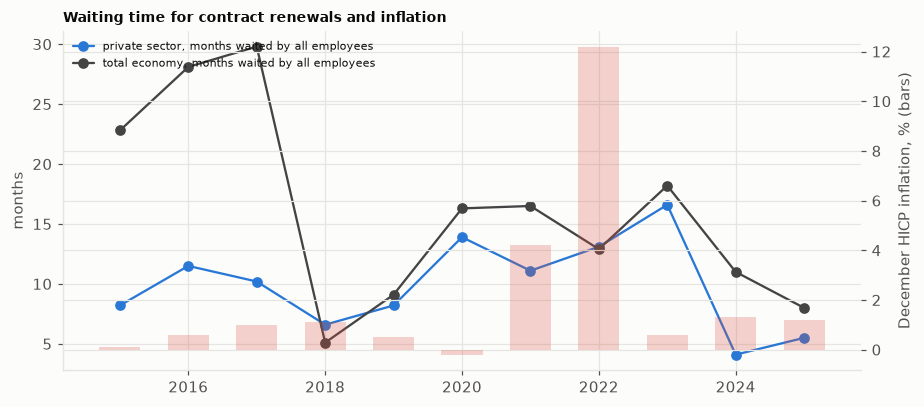

In [4]:
tn = cres["c9_tension"].copy(); tn.columns = [c if isinstance(c, str) else "|".join(x for x in c if x) for c in tn.columns]
sel = ["year", "base"] + [f"{k}|{s}" for k in ("employees_expired_pct", "months_all") for s in ("private sector", "public administration", "total economy")]
print("bargaining tension at December of each year (base 2015 up to 2020, base 2021 from 2021; not spliced): share of employees with an expired contract (%), months of waiting averaged over all employees:"); display(tn[sel].round(1))
tt = tn.set_index("year")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for s, colr in (("private sector", "#2a78d6"), ("total economy", "#444444")): ax.plot(tt.index, tt[f"months_all|{s}"], "o-", color=colr, label=f"{s}, months waited by all employees")
ax2 = ax.twinx(); ax2.bar(dec.loc[2015:2025].index, dec.loc[2015:2025].values, color="#d94f3d", alpha=.25, width=.6); ax2.set_ylabel("December HICP inflation, % (bars)")
ax.set_ylabel("months"); ax.legend(fontsize=7, loc="upper left"); ax.set_title("Waiting time for contract renewals and inflation", fontsize=9); plt.tight_layout(); plt.show()

## E. Renewal dates from CNEL's archive, and a sector deflator
The staircase proxy above infers renewals from the index. Two follow-ups, **declared before the results were seen**.

**(1) Renewal dates.** CNEL's open-data archive (`sources/cnel_contracts.py`, map in `data/external/cnel_istat_map.csv`, provenance and limits in `data/external/source/cnel/README.md`) gives the signing date and the contractual expiry of every renewal. Each Istat leaf group was mapped by hand to one CNEL contract (74 of 78 leaves; four groups with no collective contract: police, armed forces, fire brigade, the Presidency of the Council). The mapping labels are my reading of titles and signatories, not an independent second source. Cycles signed by minor unions alone are dropped when the contract has confederal (CGIL, CISL, UIL) cycles. **Primary test:** the parent groups of the `verified` leaves; x = months since the last signed renewal and months the contract had been expired at December 2021; y = the real change to 2024 and to 2025; x shuffled within the private and public branch; BH over the four tests; the staircase proxy is re-run on exactly the same groups. **Sensitivities:** the leaves, the parents with the `partly verified` leaves added, the 2016-2019 placebo and a shuffled-outcome null.

**(2) Sector deflator.** Goods HICP for agriculture, industry and construction, services HICP for private services, all-items for the public sector. Consumer prices are not the prices of a branch's output: this is a sensitivity check of the national deflator, not a better measure of the loss. Replacing the national deflator by another national one cannot change a rank correlation, so only a deflator that differs by sector matters. As a **composition check**, the national deflator is kept and x is shuffled within the sector (goods, services, public) instead of within the branch.

leaf groups mapped to a CNEL contract: 74 {'verified': 53, 'partly verified': 21} | distinct contracts: 56 | renewal signed after Dec 2021: 57 of 74
timing at December 2021, medians over the mapped leaves (months):


,months_since_renewal,months_expired,months_to_renewal
median,25.0,0.0,23.5


agreement of the staircase proxy with the dates (Spearman, mapped leaves):


,x,y,n,rho
0,staleness_months,months_since_renewal,73,0.442
1,standstill_24m,months_expired,73,0.642
2,months_to_renewal,steps_after,74,-0.075


PRIMARY (renewal dates) - parent groups of the verified leaves, x shuffled within branch, BH over four:


,x,y,n,rho,p,q_value,loo_min,loo_max
0,months_since_renewal,real_change,24,-0.358,0.084,0.169,-0.449,-0.300
1,months_since_renewal,real_change_25,24,-0.034,0.875,0.875,-0.158,0.044
2,months_expired,real_change,24,-0.541,0.005,0.022,-0.622,-0.502
3,months_expired,real_change_25,24,-0.284,0.164,0.218,-0.382,-0.223


... (16 outputs left out)

COMPOSITION - national deflator, x shuffled within sector, renewal dates:


,x,y,n,rho,p,q_value,loo_min,loo_max
0,months_since_renewal,real_change,24,-0.358,0.267,0.533,-0.449,-0.300
1,months_since_renewal,real_change_25,24,-0.034,0.914,0.914,-0.158,0.044
2,months_expired,real_change,24,-0.541,0.085,0.342,-0.622,-0.502
3,months_expired,real_change_25,24,-0.284,0.499,0.665,-0.382,-0.223


mean timing and national-deflator real change by sector of the parent groups:


,sector,n,staleness,months_since_renewal,months_expired,real_change_national
0,all-items,4,28.21,44.80,36.00,-6.64
1,goods,15,9.89,20.44,0.45,-3.92
2,services,11,34.07,41.08,22.50,-7.50


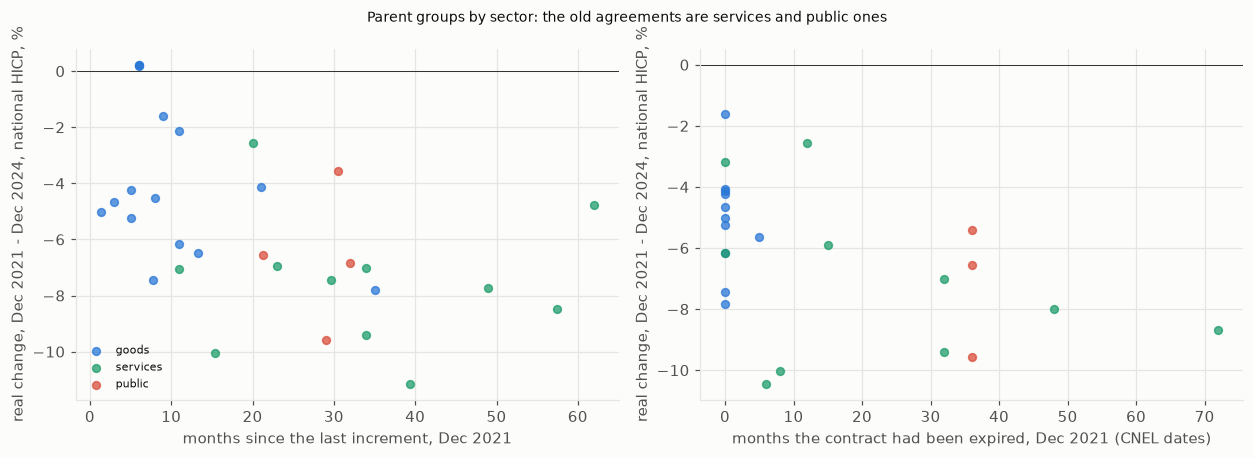

In [5]:
from cifresignificative.sources import cnel_contracts as CNm, istat_contracts as ICm
tm = cres["c13_renewal_leaves"].set_index("group")
print("leaf groups mapped to a CNEL contract:", len(tm), tm.evidence.value_counts().to_dict(), "| distinct contracts:", tm.cnel_code.nunique(), "| renewal signed after Dec 2021:", int(tm.renewed_after.sum()), "of", len(tm))
print("timing at December 2021, medians over the mapped leaves (months):"); display(tm[["months_since_renewal", "months_expired", "months_to_renewal"]].median().round(1).to_frame("median").T)
print("agreement of the staircase proxy with the dates (Spearman, mapped leaves):"); display(cres["c18_proxy_agreement"].round(3))
cols = ["x", "y", "n", "rho", "p", "q_value", "loo_min", "loo_max"]
print("PRIMARY (renewal dates) - parent groups of the verified leaves, x shuffled within branch, BH over four:"); display(cres["c14_cnel_cluster_family"][cols].round(3))
print("the staircase proxy on the same groups:"); display(cres["c15_proxy_same_clusters"][cols].round(3))
print("SENSITIVITY - verified leaves (branch shuffle, anti-conservative):"); display(cres["c16_cnel_leaf_family"][cols].round(3))
print("SENSITIVITY - parents with the partly verified leaves added (renewal dates and proxy, BH over eight):"); display(cres["c17_cnel_cluster_with_partly"][cols].round(3))
print("PLACEBO - renewal dates at December 2016, real change to December 2019:"); display(cres["c19_cnel_placebo_2016_19"][cols].round(3))
nl = cres["c20_cnel_null"]; print("shuffled-outcome null,", len(nl), "shuffles: mean discoveries", round(float(nl.discoveries.mean()), 3), "| share of p < 0.05", round(float(nl.share_p_below_005.mean()), 3))
print("cumulative HICP by component, Dec 2021 to Dec 2024 / 2025 (%):"); display(cres["c23_deflators"].pivot(index="component", columns="end", values="cumulative_pct").round(1))
print("SECTOR DEFLATOR - staircase proxy, 30 parents:"); display(cres["c21_sector_deflator_proxy"][cols].round(3))
print("SECTOR DEFLATOR - renewal dates, verified parents:"); display(cres["c22_sector_deflator_cnel"][cols].round(3))
print("COMPOSITION - national deflator, x shuffled within sector, staircase proxy (30 parents):"); display(cres["c24_proxy_within_sector"][cols].round(3))
print("COMPOSITION - national deflator, x shuffled within sector, renewal dates:"); display(cres["c25_cnel_within_sector"][cols].round(3))
print("mean timing and national-deflator real change by sector of the parent groups:"); display(cres["c26_timing_by_sector"].round(2))
defl = CT.deflator_of(ICm.load_groups()); sec = defl.reindex(leaves.index).groupby(leaves.parent).first()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2)); colr = {"goods": "#2a78d6", "services": "#1f9d6b", "all-items": "#d94f3d"}
cl_cnel = cres["c14_cnel_cluster_family"]
for ax, x, lab, d in ((axes[0], "staleness_months", "months since the last increment, Dec 2021", clu), (axes[1], "months_expired", "months the contract had been expired, Dec 2021 (CNEL dates)", None)):
    if d is None:
        t = tm[tm.evidence == "verified"].join(leaves[["parent", "real_change"]]); d = t.groupby("parent").agg(months_expired=("months_expired", "mean"), real_change=("real_change", "mean"))
    for k, c in colr.items():
        s = d[sec.reindex(d.index) == k]; ax.scatter(s[x], s.real_change, s=26, color=c, alpha=.75, label={"all-items": "public"}.get(k, k))
    ax.axhline(0, color="k", lw=.5); ax.set_xlabel(lab); ax.set_ylabel("real change, Dec 2021 - Dec 2024, national HICP, %")
axes[0].legend(fontsize=7); fig.suptitle("Parent groups by sector: the old agreements are services and public ones", fontsize=9); plt.tight_layout(); plt.show()

## F. Weighting the groups by employees
The tests above give every group the same weight, so a small sector counts as much as the 2.8 million employees of private services. CNEL and INPS publish the number of employees that declare each agreement code (December 2025, UNIEMENS; `sources/cnel_workers.py`, three Excel files kept in `data/external/source/cnel/workers/`). **Declared before the results were seen:** a leaf group gets the count of its mapped contract, split equally among the leaves that share the code; a parent group gets the sum of its leaves; the weighted statistic is the weighted Pearson correlation of the ranks (weighted Spearman) with the same within-branch permutation p (x shuffled, the weight stays with the group), BH over the four tests of the proxy family, and a shuffled-outcome null. Limits: the counts are a **2025 snapshot** used as relative weights for a 2021-24 outcome; the **public agreements (ARAN) have no count**, so every weighted test is a test on the private groups (26 of 30 parents, 64 of 78 leaves); the weighting shrinks the effective sample (Kish n_eff = (sum w)^2 / sum w^2), which is reported next to n, so a weaker p is partly lost power, not necessarily a weaker association.

In [6]:
w = cres["c31_weights"].set_index("group").sort_values("employees", ascending=False)
print("parents with a count:", int(w.employees.notna().sum()), "of", len(w), "| employees covered:", int(w.employees.sum()), "| the three largest hold", round(float(w.employees.head(3).sum() / w.employees.sum()), 3))
display(w.head(6).round(2))
print("employee-weighted against unweighted real change (leaf groups with a count):"); display(cres["c27_weighted_summary"].round(3))
cols = ["x", "y", "n", "n_eff", "rho", "rho_weighted", "p", "q_value"]
print("WEIGHTED proxy family - private parent groups, BH over four:"); display(cres["c28_weighted_proxy"][cols].round(3))
print("the same rows, unweighted (n_eff = n):"); display(cres["c29_unweighted_same_rows"][["x", "y", "n", "rho", "p", "q_value"]].round(3))
print("WEIGHTED renewal-date family - parents of the verified leaves with a count:"); display(cres["c30_weighted_cnel"][cols].round(3))
print("WEIGHTED proxy on the leaves (branch shuffle, anti-conservative):"); display(cres["c32_weighted_leaf_proxy"][cols].round(3))
nl = cres["c33_weighted_null"]; print("shuffled-outcome null of the weighted family,", len(nl), "shuffles: mean discoveries", round(float(nl.discoveries.mean()), 3), "| share of p < 0.05", round(float(nl.share_p_below_005.mean()), 3))

parents with a count: 26 of 30 | employees covered: 10187094 | the three largest hold 0.503


,employees,n_leaves,real_change,branch
group,,,,
Z1240,2752879.00,3,-10.03,private
Z1840,1370178.00,2,-9.39,private
Z2280,1005265.00,5,-7.45,private
Z0720,747384.43,3,0.20,private
Z0080,566630.00,4,-6.49,private
Z0780,498256.29,2,0.23,private


employee-weighted against unweighted real change (leaf groups with a count):


,group,n,n_with_count,employees,mean,weighted_mean,share_groups_losing,share_employees_losing,outcome
0,all,78,64,10187094.0,-5.873,-5.751,0.875,0.818,real_change
1,private,65,64,10187094.0,-5.873,-5.751,0.875,0.818,real_change
2,public,13,0,0.0,NaN,NaN,NaN,NaN,real_change
0,all,78,64,10187094.0,-4.282,-4.313,0.875,0.818,real_change_25
1,private,65,64,10187094.0,-4.282,-4.313,0.875,0.818,real_change_25
2,public,13,0,0.0,NaN,NaN,NaN,NaN,real_change_25


WEIGHTED proxy family - private parent groups, BH over four:


,x,y,n,n_eff,rho,rho_weighted,p,q_value
0,staleness_months,real_change,26,8.313,-0.600,-0.692,0.024,0.048
1,staleness_months,real_change_25,26,8.313,-0.626,-0.710,0.020,0.048
2,standstill_24m,real_change,26,8.313,-0.580,-0.571,0.098,0.098
3,standstill_24m,real_change_25,26,8.313,-0.648,-0.614,0.064,0.085


... (3 outputs left out)

,x,y,n,n_eff,rho,rho_weighted,p,q_value
0,months_since_renewal,real_change,21,6.089,-0.285,0.004,0.994,0.994
1,months_since_renewal,real_change_25,21,6.089,0.058,0.193,0.707,0.943
2,months_expired,real_change,21,6.089,-0.538,-0.503,0.227,0.870
3,months_expired,real_change_25,21,6.089,-0.292,-0.381,0.435,0.870


WEIGHTED proxy on the leaves (branch shuffle, anti-conservative):


,x,y,n,n_eff,rho,rho_weighted,p,q_value
0,staleness_months,real_change,64,11.664,-0.170,-0.092,0.681,0.687
1,staleness_months,real_change_25,64,11.664,-0.163,-0.090,0.687,0.687
2,standstill_24m,real_change,64,11.664,-0.400,-0.338,0.125,0.250
3,standstill_24m,real_change_25,64,11.664,-0.420,-0.374,0.087,0.250


shuffled-outcome null of the weighted family, 200 shuffles: mean discoveries 0.015 | share of p < 0.05 0.031


### F2. Adding the public agreements
The public groups have no CNEL-INPS count. The RGS **Conto annuale** (`sources/conto_annuale.py`; table OCCUPAZIONE, year 2021, the start of the wage window, 3.24 million heads over 47 contracts, downloaded by script) counts staff by contract, so each public leaf group gets the heads of its contract (map `data/external/conto_annuale_istat_map.csv`: ministries MNST, tax agencies AGFI, public bodies EPNE, regions and local authorities RALN, health service SSNA, research ERIC, music academies AFAM, schools SCLA, university staff UNIV, Presidency of the Council PCMD, fire brigade VVFF; police and armed forces are the sums of the contracts of the Conto annuale areas *Corpi di polizia* and *Forze armate*). The police and armed-forces groups have no CNEL contract and so no renewal date, but the staircase proxy does not need one, so they enter the proxy tests. The weights now mix a 2025 private snapshot with 2021 public heads (both heads of staff, different years: declared). Same statistics as in F, all 77 groups with a weight (the Presidency's and the others' parents included). **Note:** a parent's real change is the unweighted mean of its leaves, so the public parents (Z2560 holds ministries, health, regions and the Presidency, +5.6% for the latter) blend very different leaves; the leaf-level weighted test does not have this issue and is shown as well.

In [7]:
wa = cres["c35_weights_all"].set_index("group").sort_values("employees", ascending=False)
print("parents with a weight:", int(wa.employees.notna().sum()), "of", len(wa), "| employees covered:", int(wa.employees.sum()), "| public share:", round(float(wa[wa.branch == "public"].employees.sum() / wa.employees.sum()), 3), "| the three largest hold", round(float(wa.employees.head(3).sum() / wa.employees.sum()), 3))
display(wa.head(6).round(2))
print("employee-weighted against unweighted real change, private and public leaf groups:"); display(cres["c34_weighted_summary_all"].round(3))
cols = ["x", "y", "n", "n_eff", "rho", "rho_weighted", "p", "q_value"]
print("WEIGHTED proxy family - all 30 parents, BH over four:"); display(cres["c36_weighted_proxy_all"][cols].round(3))
print("the same rows, unweighted:"); display(cres["c37_unweighted_same_rows_all"][["x", "y", "n", "rho", "p", "q_value"]].round(3))
print("WEIGHTED proxy on the 77 leaves (branch shuffle, anti-conservative):"); display(cres["c39_weighted_leaf_proxy_all"][cols].round(3))
print("WEIGHTED renewal-date family, all verified parents:"); display(cres["c38_weighted_cnel_all"][cols].round(3))
nl = cres["c40_weighted_null_all"]; print("shuffled-outcome null of the weighted family,", len(nl), "shuffles: mean discoveries", round(float(nl.discoveries.mean()), 3), "| share of p < 0.05", round(float(nl.share_p_below_005.mean()), 3))

parents with a weight: 30 of 30 | employees covered: 13238392 | public share: 0.23 | the three largest hold 0.407


,employees,n_leaves,real_change,branch
group,,,,
Z1240,2752879.00,3,-10.03,private
Z1840,1370178.00,2,-9.39,private
Z2560,1261589.00,6,-3.56,public
Z3160,1240034.00,3,-6.57,public
Z2280,1005265.00,5,-7.45,private
Z0720,747384.43,3,0.20,private


employee-weighted against unweighted real change, private and public leaf groups:


,group,n,n_with_count,employees,mean,weighted_mean,share_groups_losing,share_employees_losing,outcome
0,all,78,77,13238392.0,-5.807,-5.933,0.883,0.860,real_change
1,private,65,64,10187094.0,-5.873,-5.751,0.875,0.818,real_change
2,public,13,13,3051298.0,-5.478,-6.541,0.923,0.999,real_change
0,all,78,77,13238392.0,-3.971,-4.305,0.857,0.847,real_change_25
1,private,65,64,10187094.0,-4.282,-4.313,0.875,0.818,real_change_25
2,public,13,13,3051298.0,-2.437,-4.276,0.769,0.946,real_change_25


WEIGHTED proxy family - all 30 parents, BH over four:


,x,y,n,n_eff,rho,rho_weighted,p,q_value
0,staleness_months,real_change,30,11.039,-0.583,-0.445,0.211,0.470
1,staleness_months,real_change_25,30,11.039,-0.551,-0.413,0.235,0.470
2,standstill_24m,real_change,30,11.039,-0.523,-0.161,0.668,0.682
3,standstill_24m,real_change_25,30,11.039,-0.513,-0.151,0.682,0.682


... (3 outputs left out)

,x,y,n,n_eff,rho,rho_weighted,p,q_value
0,staleness_months,real_change,77,15.856,-0.166,-0.129,0.479,0.538
1,staleness_months,real_change_25,77,15.856,-0.140,-0.111,0.538,0.538
2,standstill_24m,real_change,77,15.856,-0.314,-0.297,0.078,0.155
3,standstill_24m,real_change_25,77,15.856,-0.317,-0.318,0.055,0.155


WEIGHTED renewal-date family, all verified parents:


,x,y,n,n_eff,rho,rho_weighted,p,q_value
0,months_since_renewal,real_change,24,8.135,-0.358,0.096,0.856,0.856
1,months_since_renewal,real_change_25,24,8.135,-0.034,0.211,0.639,0.856
2,months_expired,real_change,24,8.135,-0.541,-0.222,0.656,0.856
3,months_expired,real_change_25,24,8.135,-0.284,-0.125,0.806,0.856


shuffled-outcome null of the weighted family, 200 shuffles: mean discoveries 0.03 | share of p < 0.05 0.029


### F3. Weights inside a parent, a second year and the special-statute contracts
F2 left three loose ends, all **chosen after F2 was seen**, so they are alternative specifications of one question, not a new test family: 8 variants are shown and none is singled out in advance. **(1) Weights inside a parent.** In F and F2 a parent's real change and timing were the *unweighted* means of its leaves while its weight was the sum of the leaves' employees, so a parent blending a large and a small leaf (the Presidency of the Council with the health service) was inconsistent. `weighted_cluster_table` averages the leaves by employees. **(2) Weighting year.** The Conto annuale of 31 December **2024** (the end of the wage window) next to 2021 (the start); the private weights stay the 2025 counts. **(3) The special-statute regions and autonomous provinces, and the Bolzano and Trento school contracts** (own contracts: REFR, RESI, RESA, REVA, RETN, PRTN, PRBZ, SCBZ, SCTN) added to the regional and school groups. Same statistics as in F, BH within each variant and family.

In [8]:
v = cres["c41_weighted_variants"]
pw_ = cres["c42_parent_weighted_means"].set_index("group")
print("parent real change, equal-weighted mean of the leaves against the employee-weighted mean (2021 weights), the groups that move most:"); display(pw_.assign(shift=pw_.real_change - pw_.real_change_unweighted_mean).sort_values("shift", key=abs, ascending=False).head(6)[["branch", "n_leaves", "employees", "real_change_unweighted_mean", "real_change", "shift"]].round(2))
c = ["year", "extended", "parent_mean", "x", "y", "n", "n_eff", "rho", "rho_weighted", "p", "q_value"]
print("PRIMARY of this section - proxy, parents with employee-weighted means, 2021 heads, BH over four:"); display(v[(v.level == "parent") & (v.family == "proxy") & (v.parent_mean == "weighted") & (v.year == 2021) & ~v.extended][c[3:]].round(3))
def pick(d, x, y):
    t = d[(d.x == x) & (d.y == y)].set_index(["parent_mean", "year", "extended"]) if len(d) else d
    return t
summary = pd.concat({"staleness, to 2024": pick(v[(v.level == "parent") & (v.family == "proxy")], "staleness_months", "real_change"), "standstill, to 2024": pick(v[(v.level == "parent") & (v.family == "proxy")], "standstill_24m", "real_change"),
                     "months expired, to 2024 (24 parents)": pick(v[(v.level == "parent") & (v.family == "cnel")], "months_expired", "real_change")})[["n_eff", "rho", "rho_weighted", "q_value"]]
print("all variants (weighted Spearman and its q; 'unweighted' = equal-weighted parent means as in F2):"); display(summary.round(3))
lf = v[(v.level == "leaf") & (v.x == "standstill_24m") & (v.y == "real_change")].set_index(["year", "extended"])[["n_eff", "rho", "rho_weighted", "q_value"]]
print("77 leaves, standstill to 2024 (branch shuffle, anti-conservative):"); display(lf.round(3))

parent real change, equal-weighted mean of the leaves against the employee-weighted mean (2021 weights), the groups that move most:


,branch,n_leaves,employees,real_change_unweighted_mean,real_change,shift
group,,,,,,
Z1240,private,3,2752879.0,-10.03,-7.50,2.54
Z2540,public,3,510789.0,-6.86,-8.89,-2.03
Z2100,private,2,303078.0,-2.57,-1.21,1.36
Z2560,public,6,1261589.0,-3.56,-4.53,-0.96
Z3160,public,3,1240034.0,-6.57,-7.53,-0.96
Z1700,private,6,388983.0,-7.05,-6.10,0.94


PRIMARY of this section - proxy, parents with employee-weighted means, 2021 heads, BH over four:


,x,y,n,n_eff,rho,rho_weighted,p,q_value
4,staleness_months,real_change,30,11.039,-0.581,-0.572,0.012,0.028
5,staleness_months,real_change_25,30,11.039,-0.551,-0.589,0.014,0.028
6,standstill_24m,real_change,30,11.039,-0.618,-0.379,0.088,0.088
7,standstill_24m,real_change_25,30,11.039,-0.621,-0.401,0.079,0.088


all variants (weighted Spearman and its q; 'unweighted' = equal-weighted parent means as in F2):


n_eff    rho  \
                                     parent_mean year extended                  
staleness, to 2024                   unweighted  2021 False     11.039 -0.583   
                                     weighted    2021 False     11.039 -0.581   
                                     unweighted  2021 True      11.029 -0.583   
                                     weighted    2021 True      11.029 -0.581   
                                     unweighted  2024 False     11.037 -0.583   
                                     weighted    2024 False     11.037 -0.581   
                                     unweighted  2024 True      11.022 -0.583   
                                     weighted    2024 True      11.022 -0.581   
standstill, to 2024                  unweighted  2021 False     11.039 -0.523   
                                     weighted    2021 False     11.039 -0.618   
                                     unweighted  2021 True      11.029 -0.523   
                                     weighted    2021 True      11.029 -0.618   
                                     unweighted  2024 False     11.037 -0.523   
                                     weighted    2024 False     11.037 -0.618   
                                     unweighted  2024 True      11.022 -0.523   
                                     weighted    2024 True      11.022 -0.618   
months expired, to 2024 (24 parents) weighted    2021 False      7.323 -0.601   
                                                      True       7.333 -0.601   
                                                 2024 False      7.346 -0.601   
                                                      True       7.351 -0.601   

                                                                rho_weighted  \
                                     parent_mean year extended                 
staleness, to 2024                   unweighted  2021 False           -0.445   
                                     weighted    2021 False           -0.572   
                                     unweighted  2021 True            -0.438   
                                     weighted    2021 True            -0.568   
                                     unweighted  2024 False           -0.439   
                                     weighted    2024 False           -0.569   
                                     unweighted  2024 True            -0.432   
                                     weighted    2024 True            -0.565   
standstill, to 2024                  unweighted  2021 False           -0.161   
                                     weighted    2021 False           -0.379   
                                     unweighted  2021 True            -0.151   
                                     weighted    2021 True            -0.371   
                                     unweighted  2024 False           -0.153   
                                     weighted    2024 False           -0.375   
                                     unweighted  2024 True            -0.143   
                                     weighted    2024 True            -0.367   
months expired, to 2024 (24 parents) weighted    2021 False           -0.410   
                                                      True            -0.399   
                                                 2024 False           -0.404   
                                                      True            -0.394   

                                                                q_value  
                                     parent_mean year extended           
staleness, to 2024                   unweighted  2021 False       0.470  
                                     weighted    2021 False       0.028  
                                     unweighted  2021 True        0.492  
                                     weighted    2021 True        0.029  
                                     unweighted  2024 False       0.481  
   

77 leaves, standstill to 2024 (branch shuffle, anti-conservative):


n_eff    rho  rho_weighted  q_value
year extended                                      
2021 False     15.856 -0.314        -0.297    0.155
     True      15.908 -0.314        -0.296    0.156
2024 False     15.841 -0.314        -0.295    0.156
     True      15.888 -0.314        -0.293    0.157

## Takeaways (Istat contractual wages by agreement group, December 2021 to December 2024/25; exploratory and descriptive)
- **Almost every agreement group lost real contractual wages in the shock.** Of the 78 leaf groups, 69 (88.5%) had a lower real contractual wage in December 2024 than in December 2021 and 67 (85.9%) in December 2025; cumulative inflation was 14.3% to 2024 and 15.7% to 2025 (December-on-December: 4.2%, 12.2%, 0.6%, 1.3%, 1.2% in 2021-2025). The median group gained 7.5% (private) and 7.3% (public) in nominal terms and lost 6.0% and 6.2% in real terms by 2024; the range is -12.5% to +5.6%. Istat's own aggregates lost less (industry -2.7%, agriculture -4.2%, private sector -4.9%, total economy -5.4% by 2024; -1.7%, -3.7%, -3.6%, -3.8% by 2025) and private services most (-7.0% and -5.3%).
- **Groups whose agreement was already old when the shock began lost more.** On the 30 parent groups, the months since the last increment at December 2021 against the real change to December 2024: rho -0.58 (to 2025: -0.55); the months without an increment among the 24 before: -0.52 (-0.51). All four tests have p about 0.001 and q 0.001 (permutation, shuffling within the private and public branch), the leave-one-group-out range of rho is -0.47 to -0.64, and the result holds for the 26 private parent groups alone (-0.60 and -0.58) and with step thresholds of 0.15% and 0.5% instead of 0.25% (staleness -0.59 and -0.50, standstill -0.53 and -0.48). Median staleness at December 2021 was 9 months for the private leaf groups and 29 for the public ones. This is the association across all parent groups; section E shows that a large part of it is a difference between sectors.
- **The check that should be flat is flat.** The same test for December 2016 to December 2019, when inflation was 2.6% in total, gives rho -0.06 (staleness) and +0.06 (standstill), p 0.87; the shuffled-outcome null gives a discovery in 4.5% of 200 shuffles (nominal about 5%).
- **The association is between parent groups, not within them.** On the 78 leaves with the branch shuffle, standstill gives -0.32 (p 0.002) and staleness -0.17 (p 0.12); shuffling within parent groups removes the between-parent variation and gives p 0.5-0.83. Sub-sectors under one parent share the national agreements and move together, so the leaf-level p-values overstate the evidence and the effective sample is the 30 parent groups; the unit was changed after the leaf-level results were seen.
- **A timing channel is consistent with the data, not shown by them.** Parent groups with an older last increment also had fewer increments in the following three years (rho -0.40 between staleness and the number of months with an increment after December 2021; -0.18 for standstill), and groups with more increments afterwards lost less (rho 0.45). That fits slow renewal of expired agreements; it does not exclude that sectors with weaker bargaining power both renew late and lose more.
- **Waiting time moved with the shock and then collapsed.** Averaged over all private-sector employees, the wait for a renewal went from 11.1 months (December 2021) to 13.1 (2022) and 16.6 (2023), then fell to 4.1 (2024) and 5.5 (2025) with the wave of renewals; the share of private employees with an expired contract was 39.8%, 35.0%, 38.0%, 37.1% and 26.1% over 2021-2025. In public administration all employees have an expired contract at almost every December (0.1% in 2018) with waits of 36.1, 12.0, 24.0, 36.0 and 16.8 months over 2021-2025: renewals come late and in bunches. The base-2015 and base-2021 series are not spliced.
- **Contract-level renewal dates give a partial confirmation, on a smaller sample.** For 53 leaves with a `verified` CNEL mapping (24 parent groups) the months the contract had been expired at December 2021 go with a larger real loss to 2024 (rho -0.54, p 0.005, q 0.022, the only one of four tests that survives), the months since the last signed renewal less so (-0.36, q 0.17), and nothing survives against the 2025 outcome (-0.28 and -0.03). The staircase proxy on the same 24 groups gives -0.36 for both measures (q 0.18): the -0.58 of the 30 parents does not carry over to this subset, and the proxy agrees only moderately with the dates (rho 0.44 for staleness against the months since renewal, 0.64 for the standstill against the months expired, n 73). On the 53 leaves with the branch shuffle the expiry gives -0.21 (q 0.29). Adding the 21 `partly verified` leaves (29 parent groups) strengthens everything (expiry -0.61, q 0.002; months since renewal -0.48, q 0.011; staleness -0.62), but that mixes evidence levels. The 2016-2019 placebo is not flat for the expiry (rho -0.39, p 0.084, q 0.17, n 21; months since renewal -0.19): a tendency for groups with an expired contract to lose real wages exists in calm years too. The shuffled-outcome null gives 0.07 discoveries per shuffle and 4.9% of p below 0.05.
- **Much of the association is a difference between sectors.** The old agreements are in services and in the public sector: mean staleness at December 2021 is 9.9 months for the 15 parent groups of agriculture and industry (goods), 34.1 for the 11 of private services and 28.2 for the 4 public ones; the months of expiry are 0.5, 22.5 and 36.0; the real change with the national deflator is -3.9%, -7.5% and -6.6%. Two checks follow. **(a) Sector deflator** (goods HICP 16.0% to 2024, services 11.3%, all-items 14.3%): the staircase proxy against the 2024 outcome falls to rho -0.14 (q 0.45) and -0.25 (q 0.26), against 2025 it stays at -0.41 and -0.44 (q 0.047 and 0.029), and the renewal dates give -0.09 to 0.11 with q 0.95. **(b) National deflator, x shuffled within sector:** rho is unchanged (-0.51 to -0.58) but the permutation p rises to 0.016-0.075 and none of the four tests survives (q 0.063-0.075); with the renewal dates the expiry gives -0.54 with q 0.34. So the data do not separate the age of an agreement from the sector it belongs to: within sectors there are only three strata, and the goods groups are almost all unexpired in December 2021 (0.5 months on average), so little variation is left there. Consumer prices are not a branch's output prices, so (a) is a sensitivity, not a better measure.
- **Weighting by employees keeps the sign and size but loses the significance, because a few agreements dominate.** CNEL-INPS counts (2025) exist for 64 of 78 leaves and 26 of 30 parents (10.2 million employees, private only; the public agreements have no count); the three largest parents hold 50.3% of them (private services 2.75 million). Weighted by employees the mean real change is -5.75% (unweighted -5.87%) and 81.8% of employees were in a group with a loss (87.5% of the groups). The weighted rank correlation of the proxy with the real change is -0.69 (staleness) and -0.57 (standstill) to 2024, -0.71 and -0.61 to 2025, against -0.60, -0.58, -0.63 and -0.65 unweighted on the same 26 parents, so the association is not carried by small sectors. The effective sample is only 8.3 groups: p 0.024 and 0.020 for staleness (BH q 0.048, the two tests that pass), 0.098 and 0.064 for standstill (q 0.098 and 0.085); the shuffled-outcome null of the weighted family is calibrated (0.015 discoveries per shuffle, 3.1% of p below 0.05). The renewal-date family does not hold once weighted (n_eff 6.1; months expired -0.50 and -0.38, q 0.87; months since renewal 0.00 and +0.19): it was already the fragile one, and it is dominated by the same few large contracts. On the 64 leaves the weighted standstill is -0.34 and -0.37 (q 0.25). Counts are a 2025 snapshot used as weights for a 2021-24 outcome and the public sector is out, so this is a check of the private-sector part.
- **Adding the public sector (Conto annuale heads, 2021) removes the weighted association.** The 13 public leaves get 3.05 million heads (23% of the 13.2 million employees covered; the three largest of the 30 parents hold 40.7%). Weighted by employees the mean real change over all 77 groups is -5.93% (unweighted -5.81%), 86.0% of employees were in a group with a loss, and in the public leaves 99.9% (weighted mean -6.54% against -5.48% unweighted: the large public groups lost most; the police and armed-forces groups, 510 thousand heads together with the fire brigade, lost 9.5% and 9.3%). On the 30 parents the weighted correlation of the proxy with the real change falls to -0.45 and -0.41 for staleness (p 0.21 and 0.24, q 0.47) and -0.16 and -0.15 for standstill (q 0.68), from -0.52 to -0.58 unweighted on the same parents; with n_eff 11.0. On the 77 leaves the weighted standstill is -0.30 and -0.32 (q 0.155) and staleness about -0.12. The renewal-date family is not weighted-significant either (q 0.86). So the association of the equal-weight tests, and the private-sector weighted result above (q 0.048 for staleness), are not robust to giving the public sector its employee weight: the largest public groups (schools -7.6%, health service -3.6%, regions and local bodies -5.5%, ministries -5.5%) have old agreements but moderate losses, and a parent's real change is the unweighted mean of very different leaves (the Presidency of the Council gained 5.6%). The shuffled-outcome null of the weighted family is calibrated (0.03 discoveries per shuffle, 2.9% of p below 0.05). Limits: heads for 2021 and 2025 mixed, the regions and the schools of Bolzano and Trento (own contracts) not in the weights, Carabinieri counted with the police, parents averaging leaves without weights.
- **Averaging the leaves by employees inside a parent brings the staleness association back; the choice is not neutral.** In F2 a parent's outcome was the equal-weighted mean of its leaves and its weight the sum of their employees. Averaging the leaves by employees instead moves a few parents a lot (commerce and services Z1240 from -10.03% to -7.50%, the police, armed forces and fire group Z2540 from -6.86% to -8.88%) and gives, with 2021 heads, a weighted rank correlation of -0.57 (to 2024) and -0.59 (to 2025) for staleness (q 0.028; n_eff 11.0) and -0.38 and -0.40 for standstill (q 0.088). The same with equal-weighted parent means (F2) was -0.45 and -0.41 (q 0.47). These are variants chosen after F2 was seen, so they are alternative specifications of one question, not independent confirmation; the version with consistent weights is the more coherent one, and the result rests on it. **The weighting year and the extra contracts change nothing:** with 2024 heads, with the special-statute regions and the Bolzano and Trento schools added, or both, the weighted staleness correlation stays between -0.565 and -0.572 (q 0.028-0.029 with weighted parent means, 0.47-0.50 with unweighted ones) and standstill between -0.367 and -0.379 (q 0.088-0.093). The renewal-date family, weighted, stays below significance (months expired -0.39 to -0.41, q 0.29-0.32, n_eff 7.3), and on the 77 leaves the weighted standstill is -0.29 to -0.30 (q 0.155-0.157). Reading the whole of section F together: the staleness association survives employee weighting only when the weights are applied consistently inside the parents, it is carried by a handful of large agreements (n_eff 11), and the equal-weight result for agreement groups is not a result for employees as a whole.
- **Limits.** The groups are Ateco sectors, not agreements, and the weights (sections F-F3) are headcounts, private from 2025 and public from 2021; 24-30 parent groups give little power for anything but a strong association; contractual wages exclude wage drift, bonuses outside the agreements and one-off payments; the number of workers per agreement is not in the flows; the mapping of Istat groups to CNEL contracts is mine, the metalworkers', air-transport and public contracts cover several groups each, one archive date may be a minor agreement (commerce 2019) and ten cycles lack a period; the real change uses national HICP, and the sector deflator is a consumer-price proxy. Associations only: an old agreement may stand for other sector characteristics, and section E suggests the sector is the main one.
